3 --> 3 points = 3 points/loop * 1 loops + 0


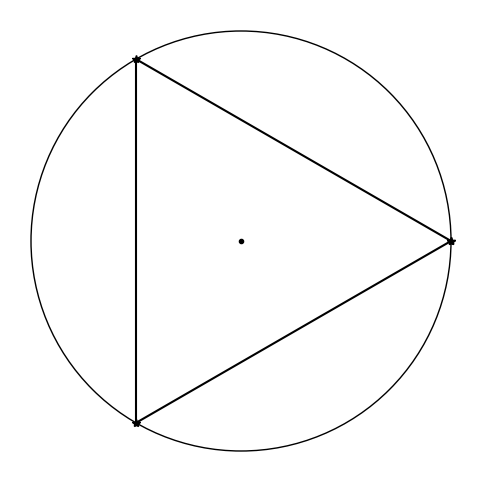

3.5 --> 7 points = 3 points/loop * 2 loops + 1


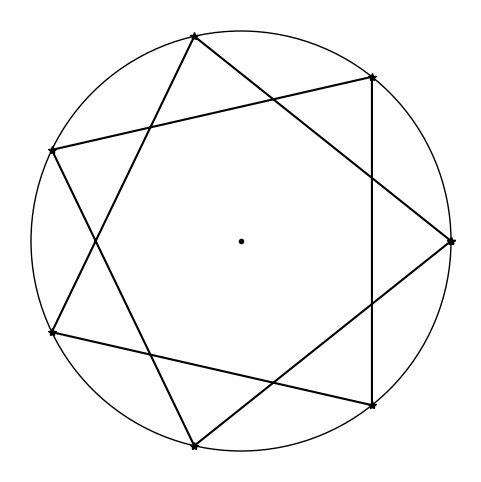

4 --> 4 points = 4 points/loop * 1 loops + 0


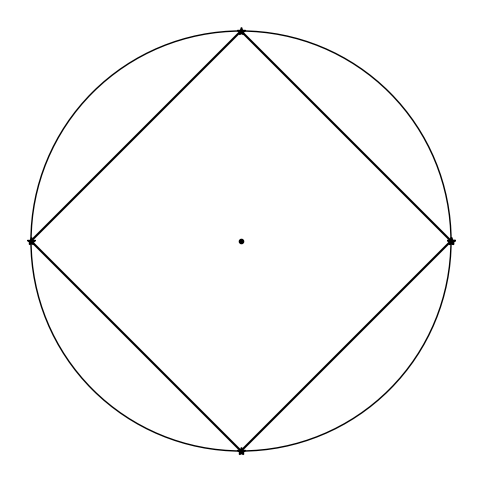

In [6]:
#%matplotlib notebook
#!pip install ipywidgets
#from ipywidgets import interact
import matplotlib.pyplot as plt
import numpy as np

def solve(n=3):
    """
    solves z^n = 1 , with complex z and real n
    """
    angle = 2*np.pi / n
    kmax = int(np.floor(n-1)) #?
    fractions = []
    repeated=False
    tol=1e-10
    k=0
    while not repeated and k<=1000:
        fracnew = (k/n)%1
        for frac in fractions:
            if np.abs(fracnew-frac)<tol:
                repeated=True
        if not repeated:
            fractions.append(fracnew)
            k+=1
    nk=len(fractions)
    nfloor = int(np.floor(n))
    nloops = int(np.floor(nk/n))
    print(f"{n} --> {nk} points = {nfloor} points/loop * {nloops} loops + {nk-nloops*nfloor}")
    z0s=list(map( lambda frac: np.exp( 1j * 2*np.pi * frac), fractions ))
    return z0s

def plot_zeros(z0s, fig=None, ax=None, line=None):
    nk=len(z0s)
    if fig is None and ax is None:
        fig,ax = plt.subplots(figsize=(6,6))
        ax.scatter(0,0,marker='.',color='k')
        circle = plt.Circle((0, 0), 1, color='k', fc='none')
        ax.add_patch(circle)
    zloop = z0s+[z0s[0]] #close the path with the starting point
    linesx = list(map( lambda z: z.real, zloop))
    linesy = list(map( lambda z: z.imag, zloop))
    if line is None:
        line = ax.plot(linesx, linesy, '*-', color='k')
    else:
        line.set_xdata(linesx)
        line.set_ydata(linesy)
    ax.set_aspect("equal")
    ax.axis('off')
    return fig,ax,line

for n in [3,3.5,4]:
    z0s = solve(n)
    fig,ax,line = plot_zeros(z0s)
    plt.show()

#def update(n = 3.0):
#    z0s = solve(n)
#    fig,ax,line = plot_zeros(z0s, fig=fig, ax=ax, line=line)
#    fig.canvas.draw_idle()
#interact(update, n = widgets.FloatSlider(value=3, min=3, max=12, step=0.01));